# 03 · Event EDA

The event stream is the foundation for almost everything that follows:
player metrics, heatmaps, pressing measures, expected threat, ratings. This
notebook works out how it is structured:

1. the hierarchy of types, subtypes and outcomes;
2. **where** each kind of event happens;
3. how events connect in **time** (possessions) and through **links**
   (`related_events`, key passes);
4. how reliable the richest single field is: StatsBomb's shot xG;
5. what can realistically be derived from all of this.

Spatial patterns that should be league-wide rather than Barcelona-specific
use the complete 2015/16 season (380 matches, all 20 clubs).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from mplsoccer import Pitch

from barca import config, pipeline
from barca.analytics import definitions as D
from barca.data import normalize
from barca.visualization import pitch as vp
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)

matches = normalize.matches(pl.read_parquet(config.INTERIM / "matches.parquet"))
events = normalize.events(pipeline.scan_events())
season_1516 = events.filter(pl.col("season") == "2015-2016")

## 1. Types, subtypes and outcomes

Each event has a `type`. Many types add a `subtype` (pass type, shot type,
duel type) and an `outcome`. Outcome vocabularies differ by type, and in
two places the *absence* of an outcome is itself the outcome:

* **Pass**: no outcome = completed;
* **Ball Receipt**: no outcome = received cleanly.

In [2]:
key_types = ["Pass", "Shot", "Duel", "Dribble", "Interception", "Goal Keeper", "50/50"]
vocab = (
    events.filter(pl.col("type").is_in(key_types))
    .group_by("type", "subtype", "outcome")
    .agg(pl.len().alias("n"))
    .collect()
    .with_columns((pl.col("n") / pl.col("n").sum().over("type")).alias("share_of_type"))
    .sort(["type", "n"], descending=[False, True])
)
vocab.group_by("type", maintain_order=True).head(6)

type,subtype,outcome,n,share_of_type
str,str,str,u32,f64
"""50/50""",null,"""Lost""",543,0.505
"""50/50""",null,"""Won""",202,0.188
"""50/50""",null,"""Success To Team""",201,0.187
"""50/50""",null,"""Success To Opposition""",129,0.120
"""Dribble""",null,"""Complete""",21311,0.588
"""Dribble""",null,"""Incomplete""",14910,0.412
"""Duel""","""Aerial Lost""",null,27896,0.449
"""Duel""","""Tackle""","""Success In Play""",11826,0.190
"""Duel""","""Tackle""","""Won""",8796,0.141


Notes that shape the metric definitions (`barca.analytics.definitions`):

* Pass subtypes are *set-piece* labels (Corner, Free Kick, Throw-in, Goal
  Kick, Kick Off) plus two open-play labels, *Recovery* and *Interception*.
  "Open play" therefore means "not one of the five set-piece types", not
  "subtype is null".
* **Tackles are Duels with subtype Tackle**; there is no Tackle type. A
  successful tackle is `Won`, `Success In Play` or `Success Out`.
* Aerial duels are split: a *lost* aerial is a Duel (`Aerial Lost`), a
  *won* one is an `aerial_won` flag on whatever the winner did with the ball
  (pass, shot, clearance).
* Shots on target are `Goal`, `Saved` and `Saved to Post`.

## 2. Where things happen

League-wide event density for 2015/16. Each pitch is normalised to its own
total, so the colour shows *where* a type happens, not how often.

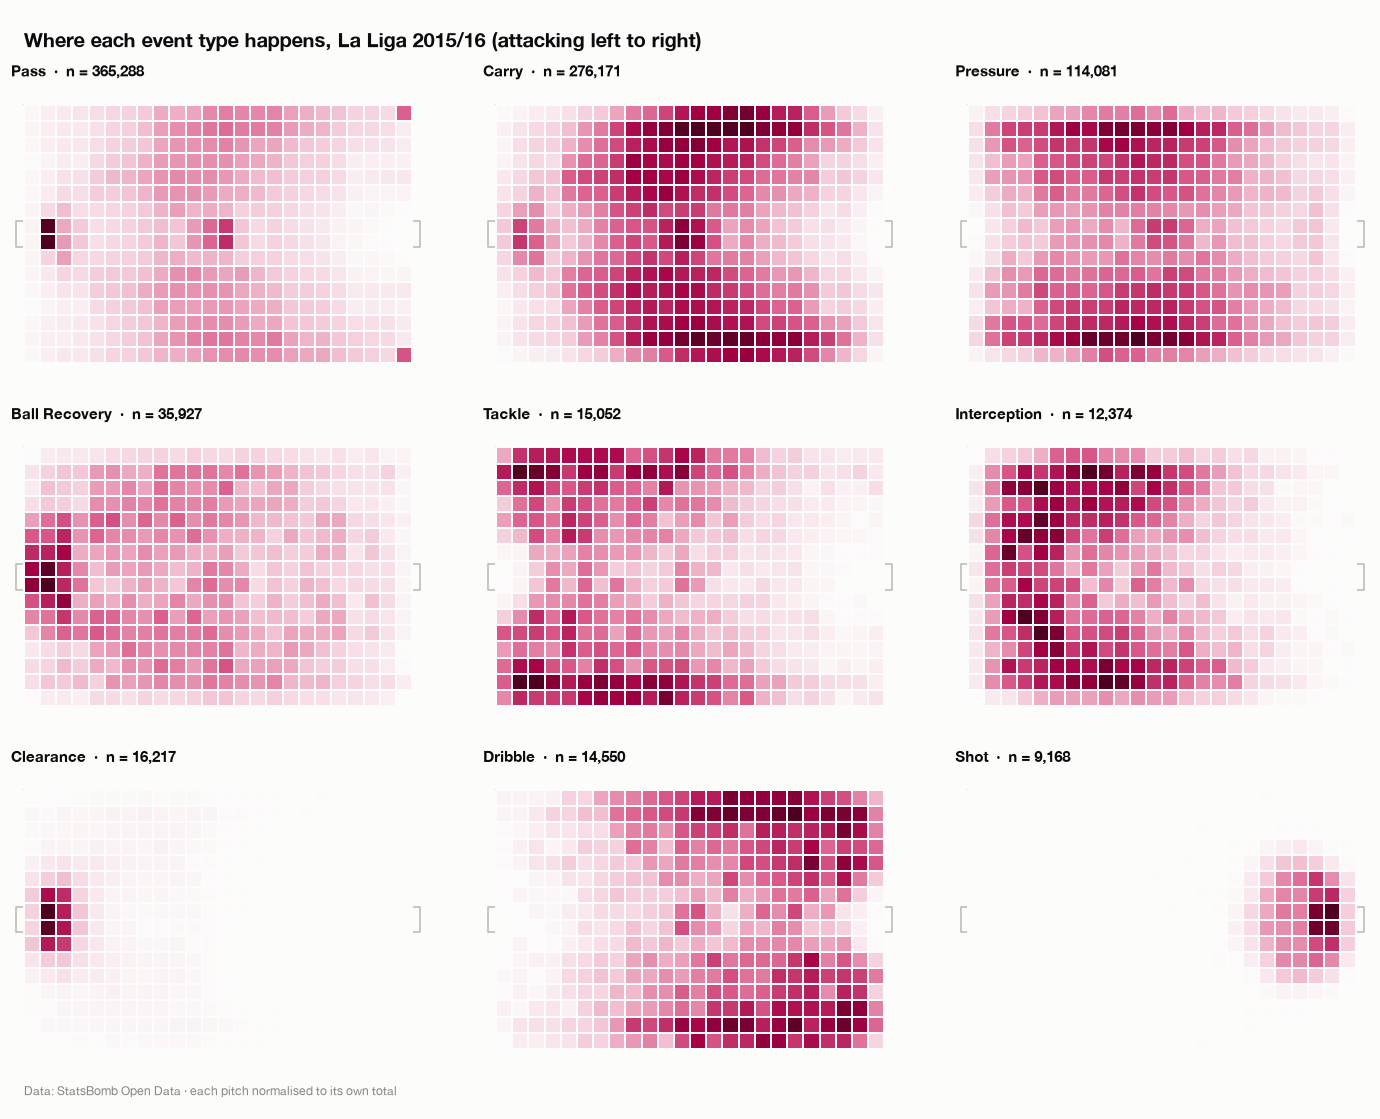

In [3]:
panel_types = [
    ("Pass", D.PASS), ("Carry", D.CARRY), ("Pressure", D.PRESSURE),
    ("Ball Recovery", D.RECOVERY), ("Tackle", D.TACKLE), ("Interception", D.INTERCEPTION),
    ("Clearance", D.CLEARANCE), ("Dribble", D.DRIBBLE), ("Shot", D.SHOT),
]
p = vp.pitch()
fig, axs = p.grid(nrows=3, ncols=3, figheight=10.5, title_height=0.05, endnote_height=0.03, axis=False,
                  grid_height=0.84, space=0.12, title_space=0.02)
for ax, (name, pred) in zip(axs["pitch"].flat, panel_types, strict=True):
    loc = season_1516.filter(pred).select("x", "y").collect()
    stats_ = p.bin_statistic(loc["x"], loc["y"], statistic="count", bins=(24, 16), normalize=True)
    p.heatmap(stats_, ax=ax, cmap=style.HEAT, edgecolors=style.SURFACE, linewidth=0.2)
    ax.set_title(f"{name}  ·  n = {loc.height:,}", fontsize=10, loc="left")
axs["title"].text(0.0, 0.5, "Where each event type happens, La Liga 2015/16 (attacking left to right)",
                  fontsize=13, fontweight="semibold", va="center")
axs["endnote"].text(0.0, 0.5, style.STATSBOMB_CREDIT + " · each pitch normalised to its own total",
                    fontsize=8, color=style.MUTED, va="center")
style.savefig(fig, "03_event_type_density")
plt.show()

The shapes are coherent and informative:

* **Passes and carries** fill the pitch but concentrate in the middle third
  and along the flanks where teams build.
* **Pressures** are highest in the middle third and in the opponent's
  half-spaces. Pressing happens far from one's own goal.
* **Recoveries, tackles and interceptions** sit mostly in a team's own half.
  **Clearances** hug the own penalty area.
* **Dribbles** are attempted in the attacking half, especially on the wings.
* **Shots** are almost entirely inside or at the edge of the box.

Because every event is recorded from the acting team's viewpoint, defensive
actions appear on the *left* (own goal). This is the property the
heatmap and zone features rely on.

## 3. Passing anatomy

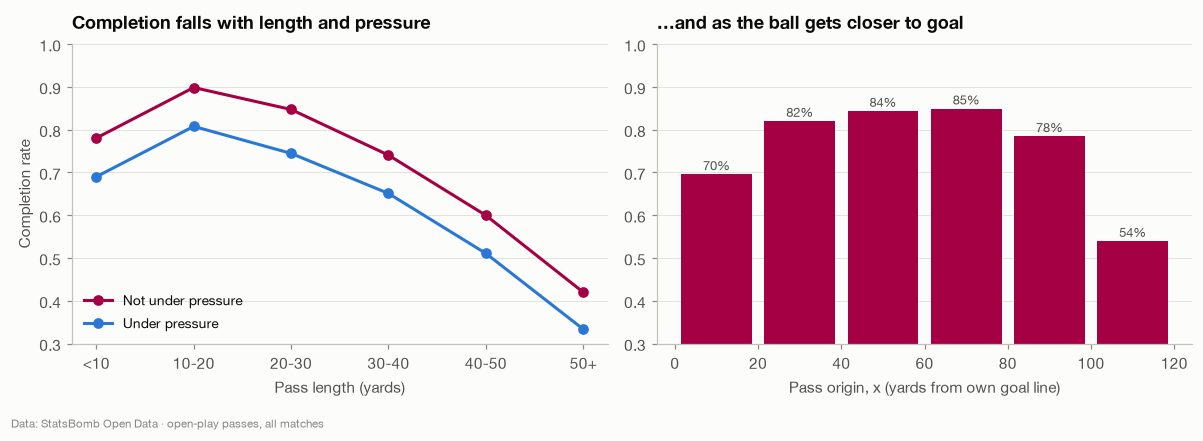

In [4]:
passes = (
    events.filter(D.PASS)
    .select("x", "y", "end_x", "pass_length", "pass_height", "under_pressure", "subtype", "outcome")
    .with_columns(
        pl.col("outcome").is_null().alias("complete"),
        pl.col("under_pressure").fill_null(False),
        pl.col("pass_length").cut([10, 20, 30, 40, 50], labels=["<10", "10-20", "20-30", "30-40", "40-50", "50+"])
        .alias("length_band"),
        (pl.col("x").clip(0, 119.9) // 20 * 20).cast(pl.Int32).alias("x_band"),
    )
    .collect()
)
open_play = passes.filter(~pl.col("subtype").is_in(D.SET_PIECE_PASS_TYPES).fill_null(False))
by_len = (
    open_play.group_by("length_band", "under_pressure")
    .agg(pl.col("complete").mean().alias("completion"), pl.len().alias("n"))
    .sort("length_band")
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bands = ["<10", "10-20", "20-30", "30-40", "40-50", "50+"]
for up, colour, label in ((False, style.BARCA, "Not under pressure"), (True, style.OPPONENT, "Under pressure")):
    d = by_len.filter(pl.col("under_pressure") == up).sort("length_band")
    axes[0].plot(range(len(d)), d["completion"], marker="o", color=colour, label=label)
axes[0].set_xticks(range(len(bands)), bands)
axes[0].set_xlabel("Pass length (yards)")
axes[0].set_ylabel("Completion rate")
axes[0].set_ylim(0.3, 1)
axes[0].set_title("Completion falls with length and pressure")
axes[0].legend(loc="lower left")

by_x = open_play.group_by("x_band").agg(pl.col("complete").mean().alias("completion"), pl.len().alias("n")).sort("x_band")
axes[1].bar(by_x["x_band"] + 10, by_x["completion"], width=17, color=style.BARCA)
for xb, c in zip(by_x["x_band"], by_x["completion"], strict=True):
    axes[1].text(xb + 10, c + 0.01, f"{c:.0%}", ha="center", fontsize=8.5, color=style.INK_2)
axes[1].set_xlabel("Pass origin, x (yards from own goal line)")
axes[1].set_ylim(0.3, 1)
axes[1].set_title("…and as the ball gets closer to goal")
style.caption(axes[0], style.STATSBOMB_CREDIT + " · open-play passes, all matches")
fig.tight_layout()
style.savefig(fig, "03_pass_completion")
plt.show()

In [5]:
passes.group_by("pass_height").agg(
    pl.len().alias("n"), pl.col("complete").mean().alias("completion"),
    pl.col("pass_length").median().alias("median_length"),
).sort("n", descending=True)

pass_height,n,completion,median_length
str,u32,f64,f32
"""Ground Pass""",581497,0.914,15.230
"""High Pass""",181304,0.459,35.393
"""Low Pass""",118787,0.728,14.268


Passing difficulty depends heavily on **length, pressure and location**:
a raw completion percentage mostly measures *which passes a player
attempts*. That is why the player analysis uses progressive and
final-third passes (and later expected threat) rather than completion rate
alone, and why "pass completion" is never presented without context.

## 4. Possessions: how events connect in time

StatsBomb assigns every event a `possession` number: a spell with one team
in control. Possessions are the natural unit for chains, pressing and
counter-attacks.

In [6]:
poss = (
    events.filter(~pl.col("type").is_in(["Starting XI", "Half Start", "Half End", "Tactical Shift",
                                         "Substitution", "Player On", "Player Off", "Injury Stoppage",
                                         "Referee Ball-Drop", "Camera On", "Camera off"]))
    .group_by("match_id", "possession")
    .agg(
        pl.col("possession_team").first(),
        pl.col("play_pattern").first(),
        pl.len().alias("events"),
        (D.PASS & (pl.col("team") == pl.col("possession_team"))).sum().alias("passes"),
        (D.PASS & (pl.col("team") != pl.col("possession_team"))).sum().alias("opponent_passes"),
        (pl.col("period_seconds").max() - pl.col("period_seconds").min()).alias("duration_s"),
        pl.col("type").last().alias("last_type"),
        D.SHOT.any().alias("has_shot"),
        pl.col("shot_xg").sum().alias("xg"),
    )
    .collect()
)
print(f"Possessions: {poss.height:,} · median events {poss['events'].median():.0f} · "
      f"median passes {poss['passes'].median():.0f} · median duration {poss['duration_s'].median():.1f}s")
poss.group_by("play_pattern").agg(
    pl.len().alias("possessions"),
    pl.col("has_shot").mean().alias("shot_rate"),
    pl.col("xg").mean().alias("xg_per_possession"),
    pl.col("passes").mean().alias("mean_passes"),
).sort("possessions", descending=True)

Possessions: 167,216 · median events 13 · median passes 3 · median duration 11.1s


play_pattern,possessions,shot_rate,xg_per_possession,mean_passes
str,u32,f64,f32,f64
"""Regular Play""",67768,0.099,0.012,5.245
"""From Throw In""",36014,0.090,0.009,5.242
"""From Free Kick""",27948,0.161,0.015,5.072
"""From Goal Kick""",13475,0.054,0.006,4.304
"""From Corner""",8583,0.338,0.035,3.456
"""From Keeper""",5657,0.048,0.006,3.227
"""From Kick Off""",4408,0.056,0.005,6.892
"""From Counter""",2913,0.295,0.050,1.922
"""Other""",450,0.564,0.444,2.089


* Most possessions are short: a median of about a dozen events (including
  ball receipts and the opponent's pressures) and only a few passes.
  Football is mostly turnovers.
* StatsBomb ends a possession only when the other team *gains control*. A
  brief opponent touch (a blocked pass, a miscued clearance) does not end
  it, so a few possessions contain opponent passes and run for minutes.
  Pass counts here only count the team in possession.
* **Counter-attacks** (`From Counter`) are rare but produce the most xG per
  possession of any open-play pattern. Corners are efficient too: the ball
  is delivered straight into the box. (`Other` is dominated by penalties,
  hence its very high xG per possession.)

Barcelona vs everyone else: how long are their possessions?

In [7]:
poss_b = poss.with_columns((pl.col("possession_team") == "Barcelona").alias("barca"))
poss_b.group_by("barca").agg(
    pl.col("passes").mean().alias("mean_passes"),
    (pl.col("passes") >= 10).mean().alias("share_10plus_passes"),
    pl.col("has_shot").mean().alias("shot_rate"),
    pl.col("xg").mean().alias("xg_per_possession"),
)

barca,mean_passes,share_10plus_passes,shot_rate,xg_per_possession
bool,f64,f64,f64,f32
false,4.146,0.091,0.105,0.011
true,6.702,0.243,0.146,0.020


Barcelona's possessions are markedly longer and more often reach ten
passes, which is the positional-play identity in one number. They also end
in a shot more often and generate more xG per possession.

## 5. How events link to each other

Three linking mechanisms make chains reconstructable:

| Link | Meaning |
|---|---|
| `related_events` | symmetric links, e.g. Pass ↔ Ball Receipt, Duel ↔ Dribble, Pressure ↔ pressured action |
| `shot_key_pass_id` | shot → the pass that created it (basis of xA) |
| `pass_assisted_shot_id` | pass → the shot it created (the reverse) |

Check that the links are consistent: every key-pass id should point at a
pass in the same match, and the reverse link should agree.

In [8]:
shots_linked = events.filter(D.SHOT, pl.col("shot_key_pass_id").is_not_null()).select(
    "match_id", pl.col("event_id").alias("shot_id"), pl.col("shot_key_pass_id").alias("pass_id")
)
pass_side = events.filter(D.PASS).select(
    "match_id", pl.col("event_id").alias("pass_id"), pl.col("pass_assisted_shot_id").alias("back_ref")
)
link_check = shots_linked.join(pass_side, on=["match_id", "pass_id"], how="left").select(
    pl.len().alias("shots_with_key_pass"),
    pl.col("back_ref").is_not_null().sum().alias("pass_found"),
    (pl.col("back_ref") == pl.col("shot_id")).sum().alias("reverse_link_agrees"),
).collect()
link_check

shots_with_key_pass,pass_found,reverse_link_agrees
u32,u32,u32
15119,15119,15119


In [9]:
rel = (
    events.filter(pl.col("type").is_in(["Pass", "Pressure", "Duel", "Dribble"]))
    .select("match_id", "type", "event_id", pl.col("related_events"))
    .explode("related_events")
    .join(events.select("match_id", pl.col("event_id").alias("related_events"), pl.col("type").alias("related_type")),
          on=["match_id", "related_events"], how="left")
    .group_by("type", "related_type").agg(pl.len().alias("n"))
    .collect()
    .with_columns((pl.col("n") / pl.col("n").sum().over("type")).alias("share"))
    .sort(["type", "n"], descending=[False, True])
)
rel.group_by("type", maintain_order=True).head(4)

type,related_type,n,share
str,str,u32,f64
"""Dribble""","""Dribbled Past""",23151,0.524
"""Dribble""","""Duel""",12999,0.294
"""Dribble""","""Pressure""",7943,0.180
"""Dribble""","""Goal Keeper""",71,0.002
"""Duel""","""Dispossessed""",21274,0.342
"""Duel""","""Pass""",18503,0.297
"""Duel""","""Dribble""",12999,0.209
"""Duel""","""Clearance""",6736,0.108
"""Pass""","""Ball Receipt*""",816400,0.709


The shot ↔ key-pass links are perfectly consistent in both directions, so
expected assists can be computed without ambiguity. `related_events` shows
the expected pairs: a Pass relates to its Ball Receipt, a Dribble to the
opponent's Dribbled Past or Duel, and a Pressure to the action it disrupted.

### One possession, reconstructed

Linking and ordering events is enough to replay a move. Below: the longest
*uninterrupted* Barcelona passing move (no opponent pass inside the
possession) that ended in a goal, showing its final 15 on-ball actions in
order. The whole move is too dense to draw legibly.

Barcelona 5-0 Levante (2015-02-15), minute 58 · 57 passes


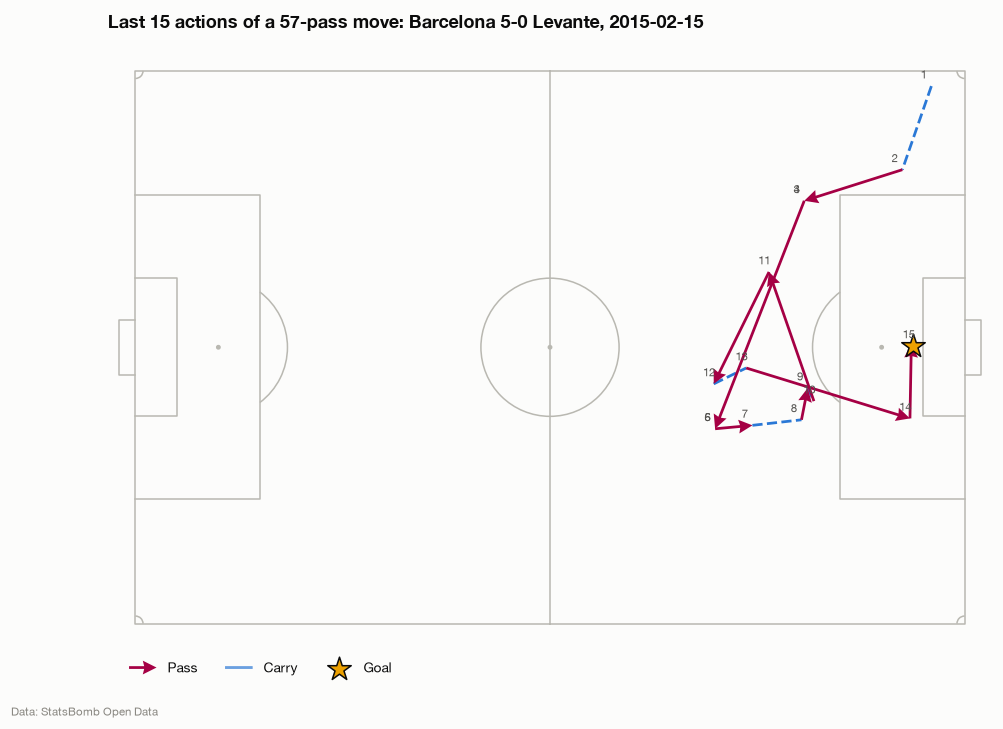

In [10]:
goal_poss = (
    poss.filter(pl.col("possession_team") == "Barcelona", pl.col("opponent_passes") == 0)
    .join(
        events.filter(D.GOAL, pl.col("team") == "Barcelona").select("match_id", "possession").unique().collect(),
        on=["match_id", "possession"],
    )
    .sort("passes", descending=True)
)
mid, pos_no = goal_poss.row(0, named=True)["match_id"], goal_poss.row(0, named=True)["possession"]
full_chain = (
    events.filter(pl.col("match_id") == mid, pl.col("possession") == pos_no,
                  pl.col("type").is_in(["Pass", "Carry", "Shot"]), pl.col("team") == "Barcelona")
    .sort("index")
    .select("type", "player", "x", "y", "end_x", "end_y", "minute", "outcome")
    .collect()
)
last_goal = full_chain.with_row_index("i").filter((pl.col("type") == "Shot") & (pl.col("outcome") == "Goal"))["i"][-1]
chain = full_chain.slice(max(0, last_goal - 14), min(15, last_goal + 1))
info = matches.filter(pl.col("match_id") == mid).row(0, named=True)
print(f"{info['home']} {info['home_score']}-{info['away_score']} {info['away']} ({info['match_date']}), "
      f"minute {chain['minute'][0]} · {goal_poss.row(0, named=True)['passes']} passes")

p = vp.pitch()
fig, ax = p.draw(figsize=(10, 6.4))
pas = chain.filter(pl.col("type") == "Pass")
car = chain.filter(pl.col("type") == "Carry")
goal = chain.filter((pl.col("type") == "Shot") & (pl.col("outcome") == "Goal"))
other_shots = chain.filter((pl.col("type") == "Shot") & (pl.col("outcome") != "Goal"))
p.arrows(pas["x"], pas["y"], pas["end_x"], pas["end_y"], ax=ax, color=style.BARCA, width=1.8,
         headwidth=5, headlength=5, zorder=3, label="Pass")
p.lines(car["x"], car["y"], car["end_x"], car["end_y"], ax=ax, color=style.OPPONENT, lw=1.8,
        linestyle="--", zorder=2, label="Carry")
if other_shots.height:
    p.scatter(other_shots["x"], other_shots["y"], ax=ax, s=90, color=style.SURFACE, edgecolor=style.INK,
              zorder=4, label="Shot (no goal)")
p.scatter(goal["x"], goal["y"], ax=ax, s=260, marker="*", color=style.THIRD, edgecolor=style.INK, zorder=5, label="Goal")
for n, (x0, y0) in enumerate(chain.select("x", "y").iter_rows(), start=1):
    ax.annotate(str(n), (x0, y0), xytext=(-7, 5), textcoords="offset points", fontsize=7.5, color=style.INK_2, zorder=6)
scorer = goal["player"][-1]
ax.legend(loc="lower left", ncols=4, fontsize=9, bbox_to_anchor=(0.01, -0.06))
ax.set_title(f"Last {chain.height} actions of a {goal_poss.row(0, named=True)['passes']}-pass move: "
             f"{info['home']} {info['home_score']}-{info['away_score']} {info['away']}, {info['match_date']}")
style.caption(ax, style.STATSBOMB_CREDIT)
style.savefig(fig, "03_longest_goal_move")
plt.show()

## 6. When things happen

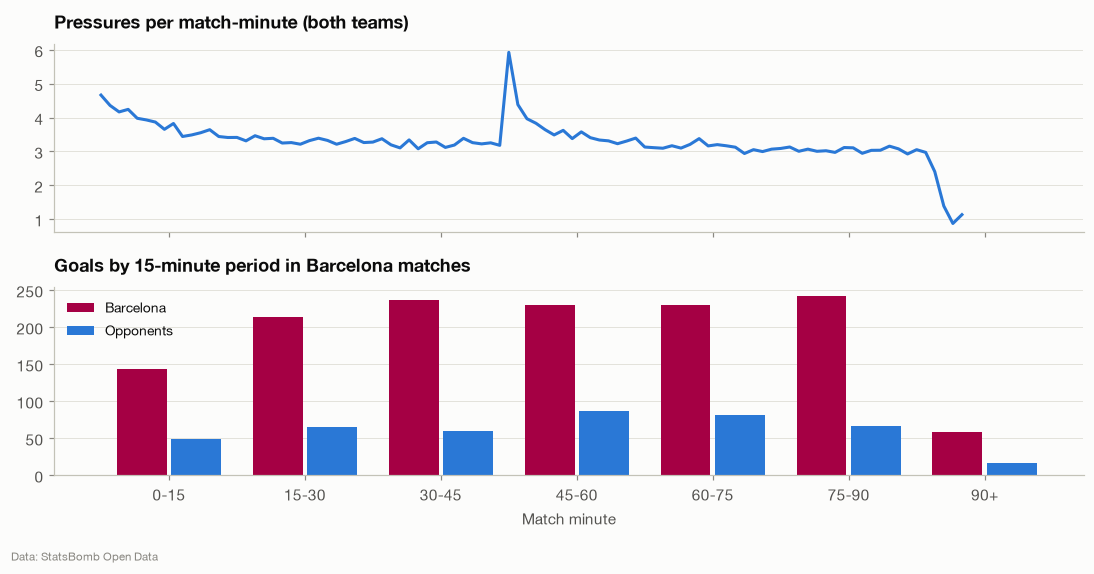

In [11]:
minute_profile = (
    events.filter(pl.col("period") <= 2)
    .with_columns(pl.col("minute").clip(0, 95))
    .group_by("minute")
    .agg(
        (D.PASS | D.CARRY).sum().alias("on_ball"),
        D.PRESSURE.sum().alias("pressures"),
        D.GOAL.sum().alias("goals"),
        pl.col("match_id").n_unique().alias("matches"),
    )
    .sort("minute")
    .collect()
)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(minute_profile["minute"], minute_profile["pressures"] / minute_profile["matches"], color=style.OPPONENT)
axes[0].set_title("Pressures per match-minute (both teams)")
barca_ids = matches.filter(pl.col("is_barca"))["match_id"].implode()
g = events.filter(D.GOAL, pl.col("period") <= 2, pl.col("match_id").is_in(barca_ids)).with_columns(
    (pl.col("minute").clip(0, 94) // 15 * 15).alias("bucket"), (pl.col("team") == "Barcelona").alias("barca")
).group_by("bucket", "barca").agg(pl.len().alias("goals")).collect()
buckets = sorted(g["bucket"].unique().to_list())
for offset, barca_flag, colour, label in ((-3, True, style.BARCA, "Barcelona"), (3, False, style.OPPONENT, "Opponents")):
    d = g.filter(pl.col("barca") == barca_flag).sort("bucket")
    axes[1].bar(d["bucket"] + 7.5 + offset, d["goals"], width=5.5, color=colour, label=label)
axes[1].set_xticks([b + 7.5 for b in buckets], [f"{b}-{b + 15}" if b < 90 else "90+" for b in buckets])
axes[1].set_title("Goals by 15-minute period in Barcelona matches")
axes[1].legend(loc="upper left")
axes[1].set_xlabel("Match minute")
style.caption(axes[1], style.STATSBOMB_CREDIT)
fig.tight_layout()
style.savefig(fig, "03_timing")
plt.show()

Pressing intensity **declines through each half**, from about 4.5 pressures
per match-minute at kick-off to about 3 late on: a fatigue signature visible
in event data. The spike at minute 45 is an artefact of the match clock:
minute 45 contains both first-half stoppage time and the first minute of the
second half, when pressing is fresh again. After 90 the rate collapses into
stoppage time.

Goals in Barcelona matches show a clear pattern: **Barcelona are slow
starters**. They score fewer goals in the opening 15 minutes than in any
other full period, and fewer than their opponents in that period. From
there Barcelona's output climbs and stays high to the end. Minute-level
context (game state, fatigue) matters when interpreting player actions.

## 7. How good is StatsBomb's xG?

xG is the most important derived field in the dataset. If it is well
calibrated, shots with xG ≈ 0.2 should be goals about 20% of the time.

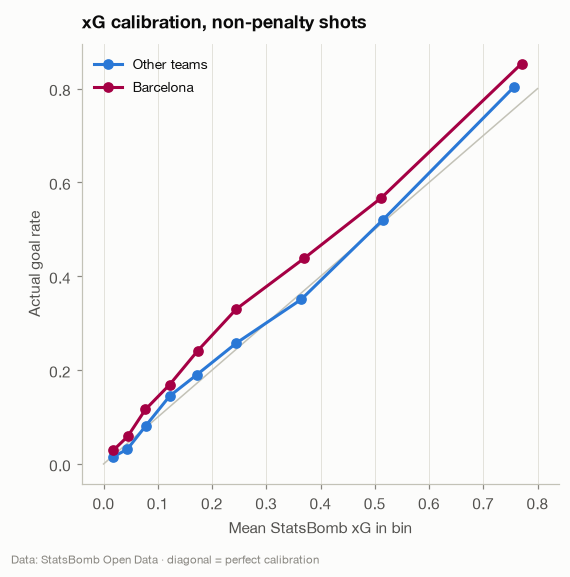

barca,shots,xg,goals,goals_per_xg
bool,u32,f32,u32,f64
true,8198,967.981,1263,1.305
false,12791,1196.571,1204,1.006


In [12]:
shots = events.filter(D.NON_PENALTY_SHOT).select(
    "shot_xg", (pl.col("outcome") == "Goal").alias("goal"), (pl.col("team") == "Barcelona").alias("barca"),
    "body_part",
).collect()
bins = [0, 0.03, 0.06, 0.1, 0.15, 0.2, 0.3, 0.45, 0.6, 1.0]
calib = (
    shots.with_columns(pl.col("shot_xg").cut(bins[1:-1]).alias("bin"))
    .group_by("barca", "bin")
    .agg(pl.col("shot_xg").mean().alias("mean_xg"), pl.col("goal").mean().alias("goal_rate"), pl.len().alias("n"))
    .sort("mean_xg")
)
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 0.8], [0, 0.8], color=style.AXIS, lw=1)
for flag, colour, label in ((False, style.OPPONENT, "Other teams"), (True, style.BARCA, "Barcelona")):
    d = calib.filter(pl.col("barca") == flag)
    ax.plot(d["mean_xg"], d["goal_rate"], marker="o", color=colour, label=label)
ax.set_xlabel("Mean StatsBomb xG in bin")
ax.set_ylabel("Actual goal rate")
ax.set_title("xG calibration, non-penalty shots")
ax.grid(axis="both")
ax.legend(loc="upper left")
style.caption(ax, style.STATSBOMB_CREDIT + " · diagonal = perfect calibration")
style.savefig(fig, "03_xg_calibration")
plt.show()

shots.group_by("barca").agg(
    pl.len().alias("shots"), pl.col("shot_xg").sum().alias("xg"), pl.col("goal").sum().alias("goals"),
).with_columns((pl.col("goals") / pl.col("xg")).alias("goals_per_xg"))

For **other teams**, goal rates track xG closely: the model is well
calibrated for an average finisher (1.01 goals per xG). **Barcelona's curve
sits above the diagonal across the whole range**, at 1.31 goals per unit of
xG. That is the same finishing edge seen in notebook 02, now visible at
shot level. It is not an artefact of a few long-range screamers; it holds
for high-quality chances too.

## 8. What can realistically be derived?

| Derivation | Built from | Where it is used |
|---|---|---|
| Per-90 player output (xG, xA, progression, defending) | typed events + minutes | player EDA, ratings |
| Progressive passes/carries, final-third and box entries | pass/carry start and end locations | team and player style |
| Pressing intensity: PPDA, counterpressing, defensive action height | Pressure, Duel, Interception, Foul locations | team style, opposition analysis |
| Possession chains and possession value (expected threat) | possession ids, event order, locations | player ratings |
| Heatmaps, zone and channel usage | event locations per player | spatial EDA, app |
| Pass networks | Pass → recipient pairs within Barcelona | app |
| Formations and positional roles | Starting XI / Tactical Shift tactics | lineup model |

What **cannot** be derived: off-ball movement, physical load (distance,
sprints), true player positions when not on the ball (except the partial
360 frames), and anything about training or injuries. Heatmaps are
therefore *action* heatmaps, not coverage maps. That limitation is carried
into the app and the limitations page.

Next: player-level analysis (`04_player_eda`).